# Overfitting, and a first look at clustering

**Video 9.6** · ShopKart project

**Goal:** See overfitting with your own eyes by growing a decision tree from depth 1 to 15, and get a first taste of unsupervised learning by grouping ShopKart customers with K-Means.

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("shopkart_clean.csv")

# Target (y): 1 if the order was returned, 0 if kept
y = (df["returned"] == "Y").astype(int)

# Features (X): things we KNOW at the time the order is placed or shipped
features = ["category", "city", "payment_mode", "delivery_days",
            "discount", "membership", "age", "unit_price"]
X = pd.get_dummies(df[features], drop_first=True, dtype=int)   # text columns -> 0/1 columns

# Same split as Video 9.4: 80% train, 20% test, same share of returns in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4000, 23)  Test: (1000, 23)


## 1. Overfitting demo
A deeper tree can memorise the training data. Memorising is not learning – the test score tells the truth.

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

results = []
for depth in range(1, 16):
    t = DecisionTreeClassifier(max_depth=depth, random_state=42)
    t.fit(X_train, y_train)
    results.append({"depth": depth,
                    "train accuracy": t.score(X_train, y_train),
                    "test accuracy": t.score(X_test, y_test)})
res = pd.DataFrame(results).round(3)
res

,depth,train accuracy,test accuracy
0,1,0.862,0.863
1,2,0.864,0.863
2,3,0.864,0.863
3,4,0.867,0.861
4,5,0.868,0.861
5,6,0.870,0.860
6,7,0.872,0.851
7,8,0.876,0.850
8,9,0.885,0.841
9,10,0.896,0.836


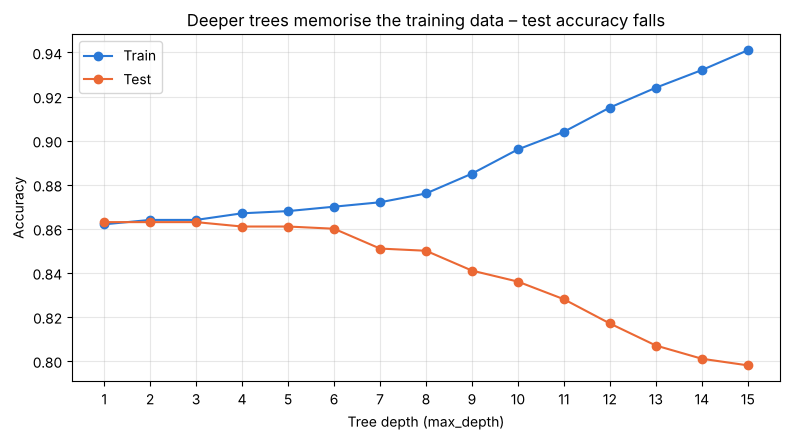

In [3]:
plt.figure(figsize=(8, 4.5))
plt.plot(res["depth"], res["train accuracy"], marker="o", color="#2a78d6", label="Train")
plt.plot(res["depth"], res["test accuracy"], marker="o", color="#eb6834", label="Test")
plt.xlabel("Tree depth (max_depth)")
plt.ylabel("Accuracy")
plt.title("Deeper trees memorise the training data – test accuracy falls")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)   # no depth limit
print("Unlimited tree -> depth", full.get_depth(),
      "| train accuracy", round(full.score(X_train, y_train), 3),
      "| test accuracy", round(full.score(X_test, y_test), 3))

Unlimited tree -> depth 31 | train accuracy 1.0 | test accuracy 0.76


**Reading the chart:** train accuracy keeps climbing towards 100% as the tree gets deeper. Test accuracy stays flat and then falls. The gap between the two lines = **overfitting**.

- Too simple (depth 1–3): underfitting – learns too little.
- Too complex (depth 10+): overfitting – learns noise, like a student mugging up answers.
- Choose the depth by looking at test (or validation) performance, not training performance.

(Remember: with only 14% returns, accuracy hides a lot – Video 9.5. The overfitting pattern is still clear.)

## 2. Bonus (not shown in the video): unsupervised learning with K-Means
In the video, Slide 35 only summarises the result in a few seconds. Run this section in your own time.
So far we always had a **target** (y). In *unsupervised* learning there is no target – the algorithm finds groups on its own. Let's group customers by how they shop.

In [5]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("shopkart_clean.csv")
cust = df.groupby("customer_id").agg(orders=("order_id", "count"),
                                     total_spend=("revenue", "sum"),
                                     avg_discount=("discount", "mean"))
scaled = StandardScaler().fit_transform(cust)          # put the 3 columns on the same scale
km = KMeans(n_clusters=3, random_state=42, n_init=10)
cust["segment"] = km.fit_predict(scaled)

summary = cust.groupby("segment").agg(customers=("orders", "size"), avg_orders=("orders", "mean"),
                                       avg_spend=("total_spend", "mean"), avg_discount=("avg_discount", "mean")).round(2)
summary

,customers,avg_orders,avg_spend,avg_discount
segment,,,,
0,292,4.96,12161.32,0.08
1,252,4.94,11899.71,0.16
2,214,10.77,38106.63,0.11


**Reading the segments:** one group orders roughly twice as often and spends about three times as much – ShopKart's loyal, high-value customers. The other two groups order about equally often, but one buys at much bigger discounts (deal hunters). Marketing could treat these three groups differently. Naming segments is a human job; K-Means only finds them. (Segment numbers 0/1/2 are arbitrary labels.)

## Where to go next
- More models: Random Forest, Gradient Boosting
- Cross-validation for more reliable scores
- Feature engineering (e.g. 'is_festive_month')
- Your capstone in Module 10: predict gym member churn with the same workflow